# Step 7 (gimbal phase 2): PD feedback to balance the rod

## 1. Where we start, what we want, what we get

| | |
|---|---|
| **We have** | the step 5 simulator, the 5 degree start, a target (upright, $q_{\text{des}}=0$, $\dot q_{\text{des}}=0$) |
| **Unknown** | the motion under feedback: does the rod reach upright and stay? |
| **Set to 0** | noise $=0$; the target angles and target rates |
| **NEW in this step** | the feedback torque from angle and rate errors |
| **What we get** | a balanced rod, a settling curve, and the closed-loop theory to compare with |
| **Pass rule** | hand vs MuJoCo with the same law: frictionless $10^{-6}$ rad, with friction $10^{-3}$ rad |

## 2. The equations

**7.1 PD law.** The command is computed from the current state before each step and held over the step:

$$c_{\text{cmd},i}=-k_p\,(q_i-q_{\text{des},i})-k_d\,(\dot q_i-\dot q_{\text{des},i})=-k_p\,q_i-k_d\,\dot q_i$$

The motor then clips and scales it (5.1). Chosen gains: $k_p=9.81$ N·m/rad, $k_d=2.52$ N·m·s/rad.

**7.2 Closed loop near upright.** Small angles: $M\approx I_p$, $\mathbf h\approx0$, $\mathbf g\approx-U_0\,q$. Substituting 7.1 into the equation of motion:

$$I_p\,\ddot q_i+(k_d+b)\,\dot q_i+(k_p-U_0)\,q_i=0$$

**7.3 Stability condition and numbers.** This is a damped oscillator, so it is stable when both coefficients are positive:

$$k_p>U_0=4.905\ \text{N·m/rad},\qquad k_d+b>0$$

$$\omega_n=\sqrt{\frac{k_p-U_0}{I_p}},\qquad \zeta=\frac{k_d+b}{2\sqrt{I_p\,(k_p-U_0)}}$$

With $k_p=9.81$: $\omega_n=3.836$ 1/s. With $k_d=2.52$ and $b=0$: $\zeta=0.985$, nearly critically damped.

**7.4 Initial torque and saturation.** At the start the command is $-k_p\,q_0=(+0.606,\ -0.605)$ N·m, well inside $\pm3$. The command saturates only when $k_p|q|>3$, that is $|q|>0.31$ rad.

**7.5 Friction offset.** With Coulomb friction the rod can stop short of upright while the net restoring torque is below $c$:

$$(k_p-U_0)\,|q_i|\le c\ \Rightarrow\ |q_i|\le\frac{0.02}{4.905}=0.004\ \text{rad}$$

| Symbol | Meaning | Unit | Status | Code name |
|---|---|---|---|---|
| $k_p$ | proportional gain | N·m/rad | **NEW**, known input (9.81) | `proportional_gain` |
| $k_d$ | derivative gain | N·m·s/rad | **NEW**, known input (2.52) | `derivative_gain` |
| $q_{\text{des}},\ \dot q_{\text{des}}$ | targets | rad, rad/s | **set to 0** (upright, still) | `target_angles`, `target_rates` |
| $\omega_n,\ \zeta$ | closed-loop frequency, damping ratio | 1/s, 1 | output | `natural_frequency`, `damping_ratio` |

## 3. Plug in, get out

```
state (q, q_dot) at the start of the step
   -> 7.1 command -> 5.1 clip and gear -> u (held over the step)
   -> 5.3 q_ddot -> RK4 -> next state
   -> compare with MuJoCo using the same law
   -> compare decay with 7.3 (omega_n, zeta)
```

## 4. Conclusion

You hold a balanced rod. The closed loop turns the unstable growth rate of $+3.8$ 1/s into a stable decay with the same speed, set by $k_p$ and $k_d$.


## Code

Names in the code follow the `Code name` columns of the tables above.

In [1]:
import os
from datetime import datetime

import numpy as np  # type: ignore
import matplotlib.pyplot as plt  # type: ignore

from mujoco_reference import run_mujoco, mujoco_mass_and_bias  # reference only: the hand code never calls MuJoCo

NOTEBOOK_NAME = "7_pd_balance"
# results of this notebook go to sim2real/modeling/result/<notebook name>/
RESULT_DIR = os.path.abspath(os.path.join(os.getcwd(), "..", "result", NOTEBOOK_NAME))
os.makedirs(RESULT_DIR, exist_ok=True)
TIMESTAMP = datetime.now().strftime("%Y%m%d_%H%M%S")
print("Saving results to:", RESULT_DIR)


Saving results to: /tmp/claude-0/-home-claude/bd8fb49c-ee3f-59e8-a19e-bae64cb3f70a/scratchpad/repo/sim2real/modeling/result/7_pd_balance


In [2]:
# ─────────────────────────────────────────────
# STEP 1: constants (equation 1.1)
# What we have: rod mass, length, radius, gravity, time step (foundational)
# What we want: pivot_inertia, axial_inertia, gravity_energy_scale (derived)
# Why: these three numbers are all the inertia and gravity terms need
# Formulas:
#   pivot_inertia = m L^2 / 3   (kg*m^2)
#   axial_inertia = m r^2 / 2   (kg*m^2)
#   gravity_energy_scale = m g L / 2   (J)
# ─────────────────────────────────────────────
gravity = 9.81  # m/s^2, foundational
rod_length = 1.0  # m, foundational
rod_mass = 1.0  # kg, foundational
rod_radius = 0.02  # m, foundational
time_step = 0.001  # s, foundational (same as MuJoCo)

pivot_inertia = rod_mass * rod_length**2 / 3  # kg*m^2, derived
axial_inertia = rod_mass * rod_radius**2 / 2  # kg*m^2, derived
gravity_energy_scale = rod_mass * gravity * rod_length / 2  # J, derived
print(f"pivot_inertia = {pivot_inertia:.5f} kg*m^2, axial_inertia = {axial_inertia:.1e} kg*m^2, gravity_energy_scale = {gravity_energy_scale:.4f} J")

START_TILT_DEG = 5  # deg, foundational test case
LEAN_DIRECTION_DEG = 45  # deg, 0 = toward +x, 90 = toward +y

VISCOUS_DAMPING_VALUE = 0.04  # N*m*s/rad, foundational (used where a run turns damping on)
COULOMB_FRICTION_VALUE = 0.02  # N*m, foundational (used where a run turns friction on)
friction_smoothing_width = 1e-3  # rad/s, foundational (tanh width, equation 3.2)

motor_gear = 1.0  # 1, foundational (gear 1: the command IS the torque)
motor_torque_limit = 3.0  # N*m, foundational (command limit of each motor)


pivot_inertia = 0.33333 kg*m^2, axial_inertia = 2.0e-04 kg*m^2, gravity_energy_scale = 4.9050 J


In [3]:
# ─────────────────────────────────────────────
# STEP 2: start angles (equation 1.2)
# What we have: start tilt and lean direction (5 and 45 degrees), start at rest
# What we want: start_angles = (outer_angle, inner_angle) in rad
# Why: the equations use hinge angles, the test case is given as tilt and direction
# Formulas:
#   inner_angle = arcsin(sin(tilt) cos(direction))
#   outer_angle = arcsin(-sin(tilt) sin(direction) / cos(inner_angle))
# ─────────────────────────────────────────────


def start_angles_from_tilt(tilt_deg, direction_deg):
    tilt = np.deg2rad(tilt_deg)
    direction = np.deg2rad(direction_deg)
    inner_angle = np.arcsin(np.sin(tilt) * np.cos(direction))
    outer_angle = np.arcsin(-np.sin(tilt) * np.sin(direction) / np.cos(inner_angle))
    return np.array([outer_angle, inner_angle])


start_angles = start_angles_from_tilt(START_TILT_DEG, LEAN_DIRECTION_DEG)  # rad
start_rates = np.zeros(2)  # rad/s, released at rest
print("start_angles =", start_angles, "rad   (expect about -0.0618, +0.0617)")


start_angles = [-0.06178509  0.06166749] rad   (expect about -0.0618, +0.0617)


In [4]:
# ─────────────────────────────────────────────
# STEP 3: physics (equations 1.3 to 1.7)
# What we have: angles and rates of the two hinges, the torque on them
# What we want: angular_acceleration (rad/s^2)
# Why: this is the physics: M q_ddot + h + g = torque
# Formulas:
#   tip_height = L cos(outer) cos(inner)
#   M = diag(M11, I_p),  M11 = I_p cos^2(inner) + I_zz sin^2(inner)
#   h1 =  (I_zz - I_p) sin(2 inner) outer_rate inner_rate;  h2 = -0.5 (I_zz - I_p) sin(2 inner) outer_rate^2
#   g1 = -U0 sin(outer) cos(inner);  g2 = -U0 cos(outer) sin(inner)
#   q_ddot = (torque - h - g) / M   (M is diagonal)
# ─────────────────────────────────────────────


def tip_height(angles):
    outer_angle, inner_angle = angles
    return rod_length * np.cos(outer_angle) * np.cos(inner_angle)  # m


def mass_matrix_diagonal(angles):
    inner_angle = angles[1]
    outer_inertia = pivot_inertia * np.cos(inner_angle) ** 2 + axial_inertia * np.sin(inner_angle) ** 2  # M11
    return np.array([outer_inertia, pivot_inertia])  # kg*m^2


def velocity_bias_torque(angles, rates):
    outer_rate, inner_rate = rates
    sin_two_inner = np.sin(2.0 * angles[1])
    return np.array([
        (axial_inertia - pivot_inertia) * sin_two_inner * outer_rate * inner_rate,
        -0.5 * (axial_inertia - pivot_inertia) * sin_two_inner * outer_rate**2,
    ])  # N*m


def gravity_torque(angles):
    outer_angle, inner_angle = angles
    return np.array([
        -gravity_energy_scale * np.sin(outer_angle) * np.cos(inner_angle),
        -gravity_energy_scale * np.cos(outer_angle) * np.sin(inner_angle),
    ])  # N*m


def viscous_torque(rates, viscous_damping):
    return -viscous_damping * rates  # N*m, equation 2.1


def coulomb_torque(rates, coulomb_friction):
    return -coulomb_friction * np.tanh(rates / friction_smoothing_width)  # N*m, equation 3.2


def angular_acceleration(angles, rates, motor_torque, viscous_damping=0.0, coulomb_friction=0.0):
    total_torque = motor_torque
    total_torque = total_torque + viscous_torque(rates, viscous_damping)
    total_torque = total_torque + coulomb_torque(rates, coulomb_friction)
    return (total_torque - velocity_bias_torque(angles, rates) - gravity_torque(angles)) / mass_matrix_diagonal(angles)  # rad/s^2


In [5]:
# ─────────────────────────────────────────────
# STEP 4: state form, RK4 and energy (equations 1.8 to 1.10)
# What we have: the acceleration function and the state (outer_angle, inner_angle, outer_rate, inner_rate)
# What we want: the state one time step later, and the energy
# Why: RK4 turns y' = f(y) into numbers; energy is the check that nothing is leaking
# Formulas:
#   f(y) = (rates, angular_acceleration)
#   k1 = f(y); k2 = f(y + dt/2 k1); k3 = f(y + dt/2 k2); k4 = f(y + dt k3)
#   y_next = y + dt/6 (k1 + 2 k2 + 2 k3 + k4)
#   E = 0.5 (M11 outer_rate^2 + I_p inner_rate^2) + U0 cos(outer) cos(inner)
# ─────────────────────────────────────────────


def state_derivative(state, motor_torque, viscous_damping=0.0, coulomb_friction=0.0):
    angles, rates = state[:2], state[2:]
    return np.concatenate([rates, angular_acceleration(angles, rates, motor_torque, viscous_damping, coulomb_friction)])


def rk4_step(state, motor_torque, time_step, viscous_damping=0.0, coulomb_friction=0.0):
    # motor_torque is held constant over all four stages, like a MuJoCo control input
    slope_1 = state_derivative(state, motor_torque, viscous_damping, coulomb_friction)
    slope_2 = state_derivative(state + 0.5 * time_step * slope_1, motor_torque, viscous_damping, coulomb_friction)
    slope_3 = state_derivative(state + 0.5 * time_step * slope_2, motor_torque, viscous_damping, coulomb_friction)
    slope_4 = state_derivative(state + time_step * slope_3, motor_torque, viscous_damping, coulomb_friction)
    return state + time_step / 6.0 * (slope_1 + 2.0 * slope_2 + 2.0 * slope_3 + slope_4)


def total_energy(state):
    angles, rates = state[:2], state[2:]
    mass_diagonal = mass_matrix_diagonal(angles)
    kinetic_energy = 0.5 * np.sum(mass_diagonal * rates**2)
    potential_energy = gravity_energy_scale * np.cos(angles[0]) * np.cos(angles[1])
    return kinetic_energy + potential_energy  # J


In [6]:
# ─────────────────────────────────────────────
# STEP 5: motor torque and the run (equations 5.1 to 5.4)
# What we have: a command function that returns the motor command from (angles, rates, step_index)
# What we want: angle, rate, energy and torque logs (row k is the state at t = (k + 1) * time_step)
# Why: the command is clipped to the motor limit and multiplied by the gear, then held constant over the step
# Formulas:
#   motor_torque = motor_gear * clip(motor_command, -motor_torque_limit, +motor_torque_limit)
# ─────────────────────────────────────────────


def motor_torque_from_command(motor_command):
    return motor_gear * np.clip(motor_command, -motor_torque_limit, motor_torque_limit)  # N*m


def simulate(start_angles, start_rates, n_steps, viscous_damping=0.0, coulomb_friction=0.0, command_function=None, stop_below_horizontal=False):
    state = np.concatenate([start_angles, start_rates])
    angle_log, rate_log, energy_log, torque_log = [], [], [], []
    for step_index in range(n_steps):
        if command_function is None:
            motor_command = np.zeros(2)
        else:
            motor_command = command_function(state[:2], state[2:], step_index)  # uses the state at the START of the step
        motor_torque = motor_torque_from_command(motor_command)
        state = rk4_step(state, motor_torque, time_step, viscous_damping, coulomb_friction)
        angle_log.append(state[:2].copy())
        rate_log.append(state[2:].copy())
        energy_log.append(total_energy(state))
        torque_log.append(motor_torque.copy())
        if stop_below_horizontal and tip_height(state[:2]) < 0:
            break
    return {"angles": np.array(angle_log), "rates": np.array(rate_log), "energy": np.array(energy_log),
            "motor_torque": np.array(torque_log)}


In [7]:
# ─────────────────────────────────────────────
# STEP 6: comparison helper (equations 4.1 to 4.3)
# What we have: a hand result and a MuJoCo result, both saved after each step
# What we want: the max abs angle error and a PASS or FAIL against a tolerance fixed BEFORE looking
# Why: index to index comparison, row k with row k
# ─────────────────────────────────────────────


def compare_angles(hand_result, mujoco_result, tolerance_rad, label):
    assert len(hand_result["angles"]) == len(mujoco_result["angles"]), f"{label}: different number of rows"
    angle_error = np.abs(hand_result["angles"] - mujoco_result["angles"])  # rad, shape (rows, 2)
    worst_error = angle_error.max()
    status = "PASS" if worst_error <= tolerance_rad else "FAIL"
    print(f"{label}: rows = {len(angle_error)}, max abs error = {worst_error:.2e} rad (tolerance {tolerance_rad:.0e}) {status}")
    assert worst_error <= tolerance_rad, f"{label}: error above tolerance"
    return angle_error


def plot_overlay(hand_result, mujoco_result, angle_error, tolerance_rad, title, file_stem):
    time_axis = (np.arange(len(angle_error)) + 1) * time_step  # s, row k is at (k + 1) dt
    figure, axes = plt.subplots(1, 2, figsize=(11, 4))
    axes[0].plot(time_axis, mujoco_result["angles"][:, 0], label="outer_angle MuJoCo")
    axes[0].plot(time_axis, hand_result["angles"][:, 0], "--", label="outer_angle hand")
    axes[0].plot(time_axis, mujoco_result["angles"][:, 1], label="inner_angle MuJoCo")
    axes[0].plot(time_axis, hand_result["angles"][:, 1], "--", label="inner_angle hand")
    axes[0].set_xlabel("time (s)")
    axes[0].set_ylabel("angle (rad)")
    axes[0].set_title(title)
    axes[0].legend()
    axes[1].semilogy(time_axis, angle_error[:, 0] + 1e-18, label="outer_angle error")
    axes[1].semilogy(time_axis, angle_error[:, 1] + 1e-18, label="inner_angle error")
    axes[1].axhline(tolerance_rad, color="k", linestyle=":", label=f"tolerance {tolerance_rad:.0e} rad")
    axes[1].set_xlabel("time (s)")
    axes[1].set_ylabel("abs error (rad)")
    axes[1].set_title("hand minus MuJoCo")
    axes[1].legend()
    figure.tight_layout()
    figure.savefig(os.path.join(RESULT_DIR, f"{file_stem}_{TIMESTAMP}.png"), dpi=150)
    print("saved the figure")
    plt.show()


In [8]:
# ─────────────────────────────────────────────
# STEP 7: PD law (equation 7.1)
# What we have: the state at the start of each step, the gains, the target (upright, still)
# What we want: motor_command for each step
# Why: feedback turns the unstable equilibrium into a stable one
# Formulas:
#   motor_command = -kp (angles - target_angles) - kd (rates - target_rates)
# ─────────────────────────────────────────────

proportional_gain = 9.81  # N*m/rad, foundational
derivative_gain = 2.52  # N*m*s/rad, foundational
target_angles = np.zeros(2)  # rad, upright
target_rates = np.zeros(2)  # rad/s, still


def pd_command(angles, rates, step_index):
    return -proportional_gain * (angles - target_angles) - derivative_gain * (rates - target_rates)


damping b = 0.0: natural_frequency = 3.836 1/s, damping_ratio = 0.985
damping b = 0.04: natural_frequency = 3.836 1/s, damping_ratio = 1.001
initial command = [ 0.60611171 -0.60495813] N*m (expect about +0.606, -0.605)


a: frictionless: rows = 3000, max abs error = 6.94e-18 rad (tolerance 1e-06) PASS
   final |angle| after 3 s = 3.55e-06 rad, largest |torque| used = 0.606 N*m


saved the figure


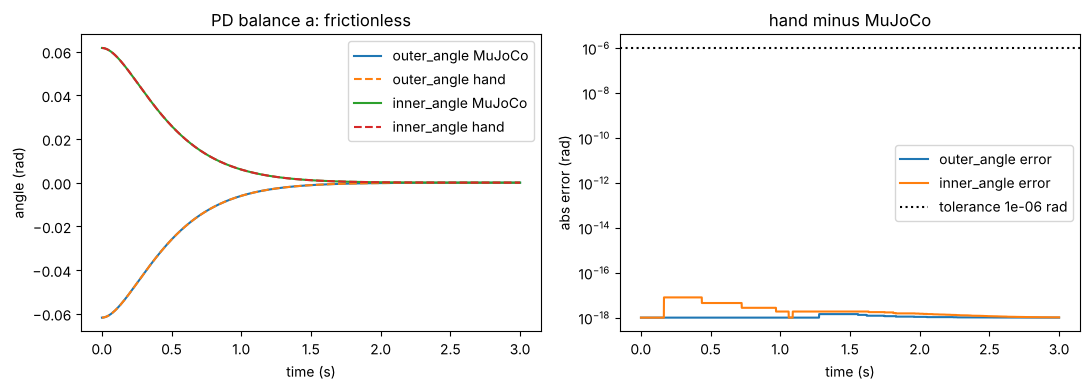

b: damping and friction: rows = 3000, max abs error = 9.07e-04 rad (tolerance 1e-03) PASS
   final |angle| after 3 s = 3.17e-03 rad, largest |torque| used = 0.606 N*m


saved the figure


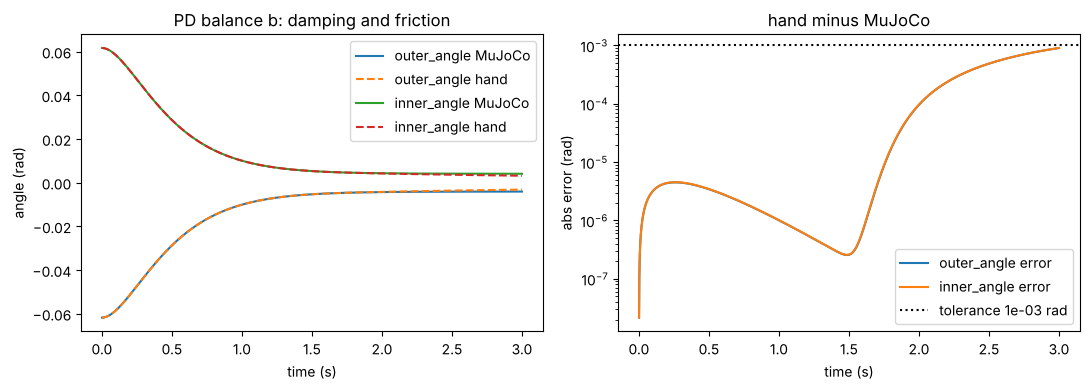

   equation 7.5 predicts the rod may stop up to 0.0041 rad short of upright
hand vs linear theory (frictionless): max gap = 1.22e-04 rad (the theory ignores the nonlinear terms)
saved the data


In [9]:
# ─────────────────────────────────────────────
# STEP 8: PD balance, hand vs MuJoCo, and the closed-loop theory (equations 7.2 to 7.5)
# What we have: the PD law with kp = 9.81 and kd = 2.52, the 5 degree start
# What we want: balanced trajectories in hand and MuJoCo, and a comparison with the linear theory
# Why: stability needs kp > U0; the decay should match natural_frequency and damping_ratio
# ─────────────────────────────────────────────

assert proportional_gain > gravity_energy_scale, "stability condition kp > U0 violated"
for damping in (0.0, VISCOUS_DAMPING_VALUE):
    natural_frequency = np.sqrt((proportional_gain - gravity_energy_scale) / pivot_inertia)  # 1/s, equation 7.3
    damping_ratio = (derivative_gain + damping) / (2 * np.sqrt(pivot_inertia * (proportional_gain - gravity_energy_scale)))
    print(f"damping b = {damping}: natural_frequency = {natural_frequency:.3f} 1/s, damping_ratio = {damping_ratio:.3f}")
print("initial command =", pd_command(start_angles, start_rates, 0), "N*m (expect about +0.606, -0.605)")

cases = [
    ("a: frictionless", 0.0, 0.0, 1e-6, "pd_case_a"),
    ("b: damping and friction", VISCOUS_DAMPING_VALUE, COULOMB_FRICTION_VALUE, 1e-3, "pd_case_b"),
]  # (label, damping, friction, tolerance in rad, file stem), tolerances fixed before looking
N_STEPS = 3000
saved_arrays = {}
for label, damping, friction, tolerance_rad, file_stem in cases:
    hand_result = simulate(start_angles, start_rates, N_STEPS, damping, friction, pd_command)
    mujoco_result = run_mujoco(start_angles, N_STEPS, damping, friction, pd_command)
    angle_error = compare_angles(hand_result, mujoco_result, tolerance_rad, label)
    final_angle = np.abs(hand_result["angles"][-1]).max()
    print(f"   final |angle| after 3 s = {final_angle:.2e} rad, largest |torque| used = {np.abs(hand_result['motor_torque']).max():.3f} N*m")
    plot_overlay(hand_result, mujoco_result, angle_error, tolerance_rad, "PD balance " + label, file_stem)
    saved_arrays[file_stem + "_angles"] = hand_result["angles"]
    saved_arrays[file_stem + "_motor_torque"] = hand_result["motor_torque"]
    if file_stem == "pd_case_b":
        print(f"   equation 7.5 predicts the rod may stop up to {friction / (proportional_gain - gravity_energy_scale):.4f} rad short of upright")

# closed-loop theory for case a (small angle): q(t) = exp(-zeta wn t) (q0 cos(wd t) + (q0_dot + zeta wn q0) / wd sin(wd t))
hand_a = simulate(start_angles, start_rates, N_STEPS, 0.0, 0.0, pd_command)
natural_frequency = np.sqrt((proportional_gain - gravity_energy_scale) / pivot_inertia)
damping_ratio = derivative_gain / (2 * np.sqrt(pivot_inertia * (proportional_gain - gravity_energy_scale)))
damped_frequency = natural_frequency * np.sqrt(1 - damping_ratio**2)
time_axis = (np.arange(N_STEPS) + 1) * time_step
theory_angles = np.exp(-damping_ratio * natural_frequency * time_axis)[:, None] * (
    start_angles * np.cos(damped_frequency * time_axis)[:, None]
    + (damping_ratio * natural_frequency * start_angles) / damped_frequency * np.sin(damped_frequency * time_axis)[:, None]
)
theory_gap = np.abs(hand_a["angles"] - theory_angles).max()
print(f"hand vs linear theory (frictionless): max gap = {theory_gap:.2e} rad (the theory ignores the nonlinear terms)")
assert theory_gap < 1e-3

np.savez(os.path.join(RESULT_DIR, f"hand_pd_{TIMESTAMP}.npz"), **saved_arrays)
print("saved the data")
